# Kidney CT classification: leakage-aware comparison of CNNs and Vision Transformers

Notebook for the thesis *Deep Learning for Kidney Abnormality Classification: A Comparative Study of CNNs and Vision Transformers* (Northern University Bangladesh).

**Pipeline**
1. Data preparation: remove exact duplicate images, random 70/15/15 split (Experiment A)
2. Near-duplicate audit with perceptual hashes
3. Leakage-controlled (cluster-aware) splits, two folds (Experiments B and C)
4. Models: ResNet50, EfficientNetB0, ConvNeXtTiny, ViT-B/16 (PyTorch + timm, full fine-tuning, 6 epochs)
5. Explainability, error concentration, class weighting, seed repeats

**Notes**
- Developed on Google Colab (T4 GPU). Paths assume the dataset zip and a Drive folder as set in the first code cell.
- Cell outputs are saved, so the results can be read without re-running.
- Training is not fully deterministic: re-running a cell can change test accuracy by several points (see the seed repeats at the end). The numbers in the saved outputs are the ones to quote.

## 1. Data preparation
Extract the zip, remove exact duplicate images (MD5 hash), and make a stratified 70/15/15 split (seed 42).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import zipfile, os, hashlib, shutil

SRC = '/content/drive/MyDrive/archive.zip'   # the zip file on Drive

os.makedirs('/content/data', exist_ok=True)
with zipfile.ZipFile(SRC) as z:
    z.extractall('/content/data')

DATA = '/content/data/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone'
classes = ['Normal', 'Cyst', 'Tumor', 'Stone']
seen, dup = {}, 0
for c in classes:
    os.makedirs(f'/content/data_dedup/{c}', exist_ok=True)
    for f in sorted(os.listdir(f'{DATA}/{c}')):
        p = f'{DATA}/{c}/{f}'
        h = hashlib.md5(open(p, 'rb').read()).hexdigest()
        if h in seen:
            dup += 1
            continue
        seen[h] = p
        shutil.copy(p, f'/content/data_dedup/{c}/{f}')
print('duplicates removed:', dup, '| unique images:', len(seen))

!pip install -q split-folders timm
import splitfolders
splitfolders.ratio('/content/data_dedup', output='/content/split_dedup', seed=42, ratio=(.7, .15, .15))

Mounted at /content/drive
duplicates removed: 517 | unique images: 11929


Copying files: 11929 files [00:07, 1619.19 files/s]


### Check: no identical files across the random split

In [ ]:
def hashes(split):
    return {hashlib.md5(open(os.path.join(r, f), 'rb').read()).hexdigest()
            for r, _, fs in os.walk(f'/content/split_dedup/{split}') for f in fs}
tr, va, te = hashes('train'), hashes('val'), hashes('test')
print('train-val:', len(tr & va), '| train-test:', len(tr & te), '| val-test:', len(va & te))

train-val: 0 | train-test: 0 | val-test: 0


## 2. Training and evaluation functions
Shared recipe: AdamW, cosine schedule, mixed precision, best-validation checkpoint, then test evaluation. `run(...)` is redefined with a `seed` argument in section 10.

In [ ]:
import time, json, numpy as np, torch, torch.nn as nn, timm
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

device = 'cuda'
SPLIT = '/content/split_dedup'
OUT = '/content/drive/MyDrive/Thesis /Final /results_dedup'
os.makedirs(OUT, exist_ok=True)

def make_loaders(mean, std, bs=32):
    tr = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(11), transforms.RandomAffine(0, translate=(0.05, 0.05), scale=(0.92, 1.08)),
        transforms.ToTensor(), transforms.Normalize(mean, std)])
    ev = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(mean, std)])
    d = {k: datasets.ImageFolder(f'{SPLIT}/{k}', tr if k == 'train' else ev) for k in ['train', 'val', 'test']}
    return d, {k: DataLoader(v, batch_size=bs, shuffle=(k == 'train'), num_workers=2) for k, v in d.items()}

@torch.no_grad()
def evaluate(m, loader):
    m.eval(); yt, yp = [], []
    for x, y in loader:
        with torch.autocast('cuda', dtype=torch.float16):
            p = m(x.to(device)).argmax(1).cpu()
        yt += y.tolist(); yp += p.tolist()
    return float(np.mean(np.array(yt) == np.array(yp))), yt, yp

def run(name, timm_name, lr, epochs=6, class_weights=False):
    torch.manual_seed(42)
    m = timm.create_model(timm_name, pretrained=True, num_classes=4).to(device)
    cfg = timm.data.resolve_data_config({}, model=m)
    d, dl = make_loaders(cfg['mean'], cfg['std'])
    classes = d['train'].classes
    w = None
    if class_weights:
        y = [s[1] for s in d['train'].samples]
        w = torch.tensor(compute_class_weight('balanced', classes=np.unique(y), y=y), dtype=torch.float).to(device)
    crit = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(dl['train']))
    scaler = torch.cuda.amp.GradScaler()
    tag = name + ('_cw' if class_weights else '')
    best = 0
    for ep in range(epochs):
        m.train(); t0 = time.time()
        for x, y in dl['train']:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.autocast('cuda', dtype=torch.float16):
                loss = crit(m(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        va = evaluate(m, dl['val'])[0]
        print(f'{tag} epoch {ep+1}/{epochs}  {time.time()-t0:.0f}s  val_acc {va:.4f}')
        if va > best:
            best = va; torch.save(m.state_dict(), f'{OUT}/{tag}.pth')
    m.load_state_dict(torch.load(f'{OUT}/{tag}.pth'))
    acc, yt, yp = evaluate(m, dl['test'])
    print(f'\n{tag}  TEST accuracy: {acc:.4f}')
    print(classification_report(yt, yp, target_names=classes))
    print(confusion_matrix(yt, yp))
    json.dump({'acc': acc, 'report': classification_report(yt, yp, target_names=classes, output_dict=True),
               'cm': confusion_matrix(yt, yp).tolist()}, open(f'{OUT}/{tag}.json', 'w'))
    del m; torch.cuda.empty_cache()

## 3. Experiment A: random split after exact-duplicate removal

In [ ]:
run('vit_b16', 'vit_base_patch16_224', 2e-5)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


vit_b16 epoch 1/6  91s  val_acc 0.9664
vit_b16 epoch 2/6  97s  val_acc 0.9961
vit_b16 epoch 3/6  95s  val_acc 0.9978
vit_b16 epoch 4/6  97s  val_acc 0.9983
vit_b16 epoch 5/6  94s  val_acc 0.9994
vit_b16 epoch 6/6  97s  val_acc 0.9994

vit_b16  TEST accuracy: 0.9983
              precision    recall  f1-score   support

        Cyst       1.00      0.99      1.00       494
      Normal       1.00      1.00      1.00       751
       Stone       0.99      1.00      0.99       205
       Tumor       1.00      1.00      1.00       343

    accuracy                           1.00      1793
   macro avg       1.00      1.00      1.00      1793
weighted avg       1.00      1.00      1.00      1793

[[491   0   3   0]
 [  0 751   0   0]
 [  0   0 205   0]
 [  0   0   0 343]]


In [ ]:
run('resnet50', 'resnet50', 1e-4)

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


resnet50 epoch 1/6  77s  val_acc 0.7931
resnet50 epoch 2/6  79s  val_acc 0.9648
resnet50 epoch 3/6  78s  val_acc 0.9821
resnet50 epoch 4/6  82s  val_acc 0.9883
resnet50 epoch 5/6  78s  val_acc 0.9894
resnet50 epoch 6/6  78s  val_acc 0.9927

resnet50  TEST accuracy: 0.9933
              precision    recall  f1-score   support

        Cyst       0.99      1.00      0.99       494
      Normal       0.99      1.00      1.00       751
       Stone       0.99      0.98      0.99       205
       Tumor       1.00      0.99      0.99       343

    accuracy                           0.99      1793
   macro avg       0.99      0.99      0.99      1793
weighted avg       0.99      0.99      0.99      1793

[[492   0   2   0]
 [  0 750   0   1]
 [  4   0 201   0]
 [  0   5   0 338]]


In [ ]:
run('convnexttiny', 'convnext_tiny', 5e-5)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


convnexttiny epoch 1/6  86s  val_acc 0.9871
convnexttiny epoch 2/6  81s  val_acc 0.9922
convnexttiny epoch 3/6  81s  val_acc 0.9950
convnexttiny epoch 4/6  83s  val_acc 0.9994
convnexttiny epoch 5/6  81s  val_acc 0.9978
convnexttiny epoch 6/6  83s  val_acc 0.9989

convnexttiny  TEST accuracy: 0.9989
              precision    recall  f1-score   support

        Cyst       1.00      1.00      1.00       494
      Normal       1.00      1.00      1.00       751
       Stone       1.00      0.99      1.00       205
       Tumor       1.00      1.00      1.00       343

    accuracy                           1.00      1793
   macro avg       1.00      1.00      1.00      1793
weighted avg       1.00      1.00      1.00      1793

[[494   0   0   0]
 [  0 751   0   0]
 [  2   0 203   0]
 [  0   0   0 343]]


In [ ]:
run('efficientnetb0', 'efficientnet_b0', 1e-4)

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


efficientnetb0 epoch 1/6  82s  val_acc 0.9698
efficientnetb0 epoch 2/6  76s  val_acc 0.9961
efficientnetb0 epoch 3/6  76s  val_acc 0.9983
efficientnetb0 epoch 4/6  77s  val_acc 0.9989
efficientnetb0 epoch 5/6  78s  val_acc 0.9994
efficientnetb0 epoch 6/6  79s  val_acc 0.9994

efficientnetb0  TEST accuracy: 0.9989
              precision    recall  f1-score   support

        Cyst       1.00      1.00      1.00       494
      Normal       1.00      1.00      1.00       751
       Stone       1.00      1.00      1.00       205
       Tumor       1.00      1.00      1.00       343

    accuracy                           1.00      1793
   macro avg       1.00      1.00      1.00      1793
weighted avg       1.00      1.00      1.00      1793

[[494   0   0   0]
 [  0 751   0   0]
 [  0   1 204   0]
 [  0   1   0 342]]


## 4. Near-duplicate audit
### 64-bit perceptual hash

In [ ]:
!pip install -q imagehash
import imagehash
from PIL import Image

def phash_split(split):
    paths = [s[0] for s in datasets.ImageFolder(f'{SPLIT}/{split}').samples]
    H = np.array([imagehash.phash(Image.open(p).convert('L')).hash.flatten() for p in paths])
    return paths, H

tr_paths, Htr = phash_split('train')
te_paths, Hte = phash_split('test')
nearest = np.array([(Hte[i] != Htr).sum(1).min() for i in range(len(Hte))])
for t in (0, 2, 4, 6, 8):
    print(f'test images with a train image within distance <= {t}: {(nearest <= t).sum()} ({(nearest <= t).mean()*100:.1f}%)')

test images with a train image within distance <= 0: 1126 (62.8%)
test images with a train image within distance <= 2: 1736 (96.8%)
test images with a train image within distance <= 4: 1785 (99.6%)
test images with a train image within distance <= 6: 1791 (99.9%)
test images with a train image within distance <= 8: 1793 (100.0%)


### 256-bit perceptual hash: distance from each test image to its nearest train image

In [ ]:
!pip install -q imagehash
import imagehash, numpy as np, matplotlib.pyplot as plt
from PIL import Image

# 256-bit hash for every unique image
paths, labels = [], []
for ci, c in enumerate(sorted(os.listdir('/content/data_dedup'))):
    for f in sorted(os.listdir(f'/content/data_dedup/{c}')):
        paths.append(f'/content/data_dedup/{c}/{f}'); labels.append(ci)
labels = np.array(labels)
H = np.array([imagehash.phash(Image.open(p).convert('L'), hash_size=16).hash.flatten() for p in paths]).astype(np.float32)
print('hashed:', H.shape)

def hamming(A, B):
    return A.sum(1)[:, None] + B.sum(1)[None, :] - 2 * A @ B.T

key = {(os.path.basename(os.path.dirname(p)), os.path.basename(p)): i for i, p in enumerate(paths)}
def split_idx(split):
    return np.array([key[(c, f)] for c in os.listdir(f'{SPLIT}/{split}') for f in os.listdir(f'{SPLIT}/{split}/{c}')])
tr_i, te_i = split_idx('train'), split_idx('test')

# nearest train image for every test image (256-bit scale)
nearest = np.concatenate([hamming(H[te_i[s:s+300]], H[tr_i]).min(1) for s in range(0, len(te_i), 300)])
for t in (0, 8, 16, 32, 64):
    print(f'test images with a train image within {t}/256 bits: {(nearest <= t).sum()} ({(nearest <= t).mean()*100:.1f}%)')

hashed: (11929, 256)
test images with a train image within 0/256 bits: 42 (2.3%)
test images with a train image within 8/256 bits: 1424 (79.4%)
test images with a train image within 16/256 bits: 1756 (97.9%)
test images with a train image within 32/256 bits: 1790 (99.8%)
test images with a train image within 64/256 bits: 1793 (100.0%)


### Visual check: random test images next to their nearest train image

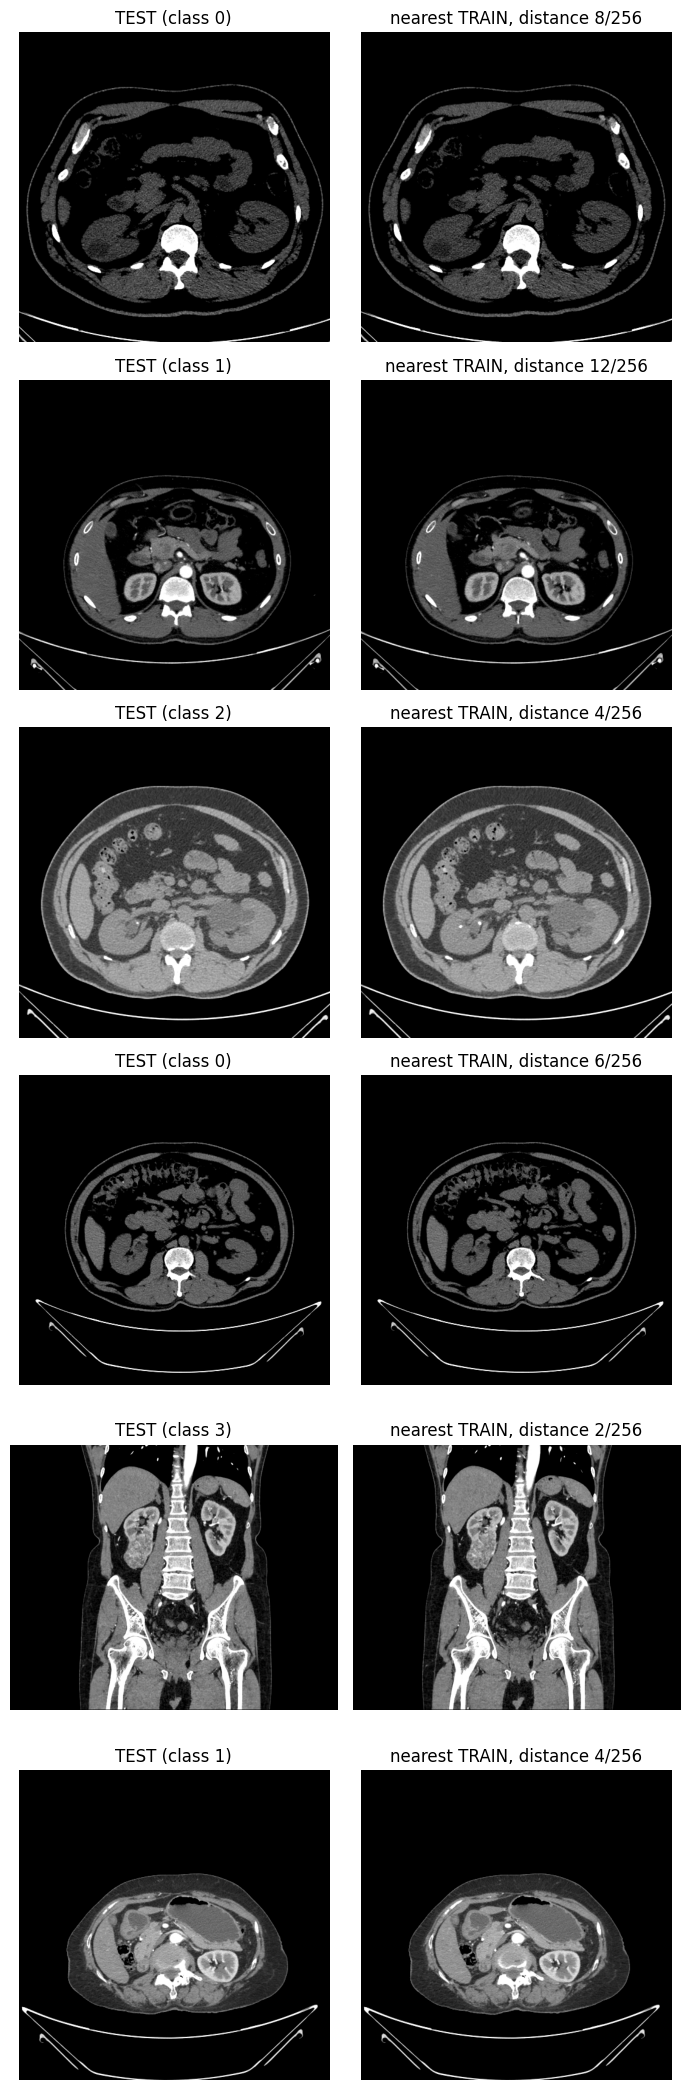

In [ ]:
rng = np.random.default_rng(0)
pick = rng.choice(len(te_i), 6, replace=False)
fig, ax = plt.subplots(6, 2, figsize=(7, 21))
for r, k in enumerate(pick):
    i = te_i[k]
    d = hamming(H[i:i+1], H[tr_i])[0]
    j = tr_i[d.argmin()]
    ax[r, 0].imshow(Image.open(paths[i]), cmap='gray'); ax[r, 0].set_title(f'TEST (class {labels[i]})')
    ax[r, 1].imshow(Image.open(paths[j]), cmap='gray'); ax[r, 1].set_title(f'nearest TRAIN, distance {int(d.min())}/256')
    for a in ax[r]: a.axis('off')
plt.tight_layout(); plt.show()

## 5. Leakage-controlled split (cluster-aware)
Images within 12 bits of each other are grouped into clusters, and whole clusters are assigned to train, validation or test.

In [ ]:
import shutil
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

N = len(H)
def clusters(t):
    rows, cols = [], []
    for s in range(0, N, 500):
        r, c = np.where(hamming(H[s:s+500], H) <= t)
        rows.append(r + s); cols.append(c)
    r, c = np.concatenate(rows), np.concatenate(cols)
    return connected_components(csr_matrix((np.ones(len(r)), (r, c)), shape=(N, N)), directed=False)

for T in (12, 8, 6, 4):
    n, lab = clusters(T)
    sz = np.bincount(lab)
    print(f'<= {T}/256 bits: {n} clusters, largest = {sz.max()} ({sz.max()/N*100:.1f}% of all images)')
    if sz.max() <= 0.05 * N:
        break
print('using threshold', T)
print('clusters with more than one class:', sum(len(set(labels[lab == k])) > 1 for k in range(n)))

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
folds = [te for _, te in sgkf.split(np.zeros(N), labels, groups=lab)]
assign = {}
for i in folds[0]: assign[i] = 'test'
for i in folds[1]: assign[i] = 'val'
for f in folds[2:]:
    for i in f: assign[i] = 'train'

SPLITG = '/content/split_group'
cls_names = sorted(os.listdir('/content/data_dedup'))
for sp in ('train', 'val', 'test'):
    for c in cls_names:
        os.makedirs(f'{SPLITG}/{sp}/{c}', exist_ok=True)
for i, sp in assign.items():
    shutil.copy(paths[i], f'{SPLITG}/{sp}/{cls_names[labels[i]]}/{os.path.basename(paths[i])}')
print({sp: sum(v == sp for v in assign.values()) for sp in ('train', 'val', 'test')})

# leakage check on the new split
tr2 = np.array([i for i, s in assign.items() if s == 'train'])
te2 = np.array([i for i, s in assign.items() if s == 'test'])
near2 = np.concatenate([hamming(H[te2[s:s+300]], H[tr2]).min(1) for s in range(0, len(te2), 300)])
for t in (0, 8, 16, 32):
    print(f'test images with a train image within {t}/256 bits: {(near2 <= t).mean()*100:.1f}%  (old split: see earlier)')

<= 12/256 bits: 771 clusters, largest = 173 (1.5% of all images)
using threshold 12
clusters with more than one class: 0
{'train': 8789, 'val': 1442, 'test': 1698}
test images with a train image within 0/256 bits: 0.0%  (old split: see earlier)
test images with a train image within 8/256 bits: 0.0%  (old split: see earlier)
test images with a train image within 16/256 bits: 5.5%  (old split: see earlier)
test images with a train image within 32/256 bits: 20.8%  (old split: see earlier)


## 6. Experiment B: cluster-aware split, fold 1

In [ ]:
SPLIT = '/content/split_group'
OUT = '/content/drive/MyDrive/Thesis /Final /results_group'
os.makedirs(OUT, exist_ok=True)

In [ ]:
run('vit_b16', 'vit_base_patch16_224', 2e-5)

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


vit_b16 epoch 1/6  102s  val_acc 0.9736
vit_b16 epoch 2/6  97s  val_acc 0.9196
vit_b16 epoch 3/6  92s  val_acc 0.9820
vit_b16 epoch 4/6  98s  val_acc 0.9799
vit_b16 epoch 5/6  92s  val_acc 0.9820
vit_b16 epoch 6/6  91s  val_acc 0.9827

vit_b16  TEST accuracy: 0.9293
              precision    recall  f1-score   support

        Cyst       0.92      0.89      0.90       503
      Normal       0.95      1.00      0.97       505
       Stone       0.85      0.90      0.87       359
       Tumor       1.00      0.92      0.96       331

    accuracy                           0.93      1698
   macro avg       0.93      0.93      0.93      1698
weighted avg       0.93      0.93      0.93      1698

[[446   0  57   0]
 [  0 504   0   1]
 [ 37   0 322   0]
 [  0  25   0 306]]


In [ ]:
run('resnet50', 'resnet50', 1e-4)

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


resnet50 epoch 1/6  78s  val_acc 0.8564
resnet50 epoch 2/6  79s  val_acc 0.9133
resnet50 epoch 3/6  79s  val_acc 0.9535
resnet50 epoch 4/6  81s  val_acc 0.9660
resnet50 epoch 5/6  79s  val_acc 0.9674
resnet50 epoch 6/6  78s  val_acc 0.9688

resnet50  TEST accuracy: 0.9058
              precision    recall  f1-score   support

        Cyst       0.89      0.89      0.89       503
      Normal       0.95      0.97      0.96       505
       Stone       0.84      0.83      0.83       359
       Tumor       0.94      0.92      0.93       331

    accuracy                           0.91      1698
   macro avg       0.90      0.90      0.90      1698
weighted avg       0.91      0.91      0.91      1698

[[447   0  56   0]
 [  0 488   1  16]
 [ 56   1 297   5]
 [  1  24   0 306]]


In [ ]:
run('convnexttiny', 'convnext_tiny', 5e-5)

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


convnexttiny epoch 1/6  83s  val_acc 0.9903
convnexttiny epoch 2/6  82s  val_acc 0.9570
convnexttiny epoch 3/6  82s  val_acc 0.9972
convnexttiny epoch 4/6  88s  val_acc 0.9938
convnexttiny epoch 5/6  81s  val_acc 0.9938
convnexttiny epoch 6/6  82s  val_acc 0.9931

convnexttiny  TEST accuracy: 0.9700
              precision    recall  f1-score   support

        Cyst       0.96      0.98      0.97       503
      Normal       0.97      1.00      0.98       505
       Stone       0.97      0.94      0.95       359
       Tumor       1.00      0.95      0.97       331

    accuracy                           0.97      1698
   macro avg       0.97      0.97      0.97      1698
weighted avg       0.97      0.97      0.97      1698

[[492   0  11   0]
 [  0 505   0   0]
 [ 23   0 336   0]
 [  0  17   0 314]]


In [ ]:
run('efficientnetb0', 'efficientnet_b0', 1e-4)

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


efficientnetb0 epoch 1/6  78s  val_acc 0.8994
efficientnetb0 epoch 2/6  77s  val_acc 0.9286
efficientnetb0 epoch 3/6  77s  val_acc 0.9556
efficientnetb0 epoch 4/6  82s  val_acc 0.9688
efficientnetb0 epoch 5/6  79s  val_acc 0.9605
efficientnetb0 epoch 6/6  82s  val_acc 0.9612

efficientnetb0  TEST accuracy: 0.7845
              precision    recall  f1-score   support

        Cyst       0.92      0.80      0.85       503
      Normal       0.69      0.94      0.80       505
       Stone       0.66      0.60      0.63       359
       Tumor       0.97      0.73      0.83       331

    accuracy                           0.78      1698
   macro avg       0.81      0.77      0.78      1698
weighted avg       0.81      0.78      0.78      1698

[[400  14  89   0]
 [  1 474  22   8]
 [ 33 110 216   0]
 [  0  89   0 242]]


### Split diagnostics: class mix, and validation/test distance to train

In [ ]:
va2 = np.array([i for i, s in assign.items() if s == 'val'])
for nm, idx in (('train', tr2), ('val', va2), ('test', te2)):
    print(nm, dict(zip(cls_names, np.bincount(labels[idx], minlength=4))))
near_val = np.concatenate([hamming(H[va2[s:s+300]], H[tr2]).min(1) for s in range(0, len(va2), 300)])
for t in (8, 16, 32):
    print(f'within {t}/256 bits of a train image -> val: {(near_val <= t).mean()*100:.1f}%  | test: {(near2 <= t).mean()*100:.1f}%')

train {'Cyst': np.int64(2374), 'Normal': np.int64(3744), 'Stone': np.int64(912), 'Tumor': np.int64(1759)}
val {'Cyst': np.int64(407), 'Normal': np.int64(753), 'Stone': np.int64(89), 'Tumor': np.int64(193)}
test {'Cyst': np.int64(503), 'Normal': np.int64(505), 'Stone': np.int64(359), 'Tumor': np.int64(331)}
within 8/256 bits of a train image -> val: 0.0%  | test: 0.0%
within 16/256 bits of a train image -> val: 6.4%  | test: 5.5%
within 32/256 bits of a train image -> val: 25.1%  | test: 20.8%


## 7. Experiment C: cluster-aware split, fold 2

In [ ]:
def build_split(test_fold, val_fold, out):
    assign2 = {}
    for k, f in enumerate(folds):
        sp = 'test' if k == test_fold else 'val' if k == val_fold else 'train'
        for i in f:
            assign2[i] = sp
    if os.path.exists(out):
        shutil.rmtree(out)
    for sp in ('train', 'val', 'test'):
        for c in cls_names:
            os.makedirs(f'{out}/{sp}/{c}', exist_ok=True)
    for i, sp in assign2.items():
        shutil.copy(paths[i], f'{out}/{sp}/{cls_names[labels[i]]}/{os.path.basename(paths[i])}')
    for sp in ('train', 'val', 'test'):
        idx = np.array([i for i, s in assign2.items() if s == sp])
        print(sp, len(idx), dict(zip(cls_names, np.bincount(labels[idx], minlength=4))))

build_split(test_fold=3, val_fold=4, out='/content/split_group2')
SPLIT = '/content/split_group2'
OUT = '/content/drive/MyDrive/Thesis /Final /results_group2'
os.makedirs(OUT, exist_ok=True)

train 8108 {'Cyst': np.int64(2380), 'Normal': np.int64(3099), 'Stone': np.int64(1068), 'Tumor': np.int64(1561)}
val 1635 {'Cyst': np.int64(567), 'Normal': np.int64(664), 'Stone': np.int64(165), 'Tumor': np.int64(239)}
test 2186 {'Cyst': np.int64(337), 'Normal': np.int64(1239), 'Stone': np.int64(127), 'Tumor': np.int64(483)}


In [ ]:
run('convnexttiny', 'convnext_tiny', 5e-5)

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


convnexttiny epoch 1/6  87s  val_acc 0.9896
convnexttiny epoch 2/6  81s  val_acc 0.9621
convnexttiny epoch 3/6  79s  val_acc 0.9914
convnexttiny epoch 4/6  80s  val_acc 0.9963
convnexttiny epoch 5/6  80s  val_acc 0.9963
convnexttiny epoch 6/6  80s  val_acc 0.9963

convnexttiny  TEST accuracy: 0.9762
              precision    recall  f1-score   support

        Cyst       0.95      0.99      0.97       337
      Normal       0.98      1.00      0.99      1239
       Stone       0.98      0.99      0.99       127
       Tumor       0.99      0.91      0.95       483

    accuracy                           0.98      2186
   macro avg       0.98      0.97      0.97      2186
weighted avg       0.98      0.98      0.98      2186

[[ 335    0    2    0]
 [   0 1235    0    4]
 [   1    0  126    0]
 [  15   30    0  438]]


In [ ]:
run('vit_b16', 'vit_base_patch16_224', 2e-5)

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


vit_b16 epoch 1/6  90s  val_acc 0.9187
vit_b16 epoch 2/6  90s  val_acc 0.9639
vit_b16 epoch 3/6  93s  val_acc 0.9798
vit_b16 epoch 4/6  95s  val_acc 0.9602
vit_b16 epoch 5/6  89s  val_acc 0.9645
vit_b16 epoch 6/6  90s  val_acc 0.9645

vit_b16  TEST accuracy: 0.9707
              precision    recall  f1-score   support

        Cyst       0.93      0.99      0.96       337
      Normal       0.97      1.00      0.98      1239
       Stone       0.98      1.00      0.99       127
       Tumor       1.00      0.87      0.93       483

    accuracy                           0.97      2186
   macro avg       0.97      0.97      0.97      2186
weighted avg       0.97      0.97      0.97      2186

[[ 335    0    2    0]
 [   0 1239    0    0]
 [   0    0  127    0]
 [  24   38    0  421]]


In [ ]:
run('resnet50', 'resnet50', 1e-4)

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


resnet50 epoch 1/6  76s  val_acc 0.7291
resnet50 epoch 2/6  75s  val_acc 0.8685
resnet50 epoch 3/6  77s  val_acc 0.8991
resnet50 epoch 4/6  79s  val_acc 0.9089
resnet50 epoch 5/6  76s  val_acc 0.9028
resnet50 epoch 6/6  75s  val_acc 0.9131

resnet50  TEST accuracy: 0.9076
              precision    recall  f1-score   support

        Cyst       0.91      0.99      0.95       337
      Normal       0.92      0.98      0.95      1239
       Stone       0.69      0.96      0.80       127
       Tumor       0.97      0.64      0.77       483

    accuracy                           0.91      2186
   macro avg       0.87      0.89      0.87      2186
weighted avg       0.92      0.91      0.90      2186

[[ 332    0    5    0]
 [   0 1220    8   11]
 [   5    0  122    0]
 [  26  104   43  310]]


In [ ]:
run('efficientnetb0', 'efficientnet_b0', 1e-4)

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


efficientnetb0 epoch 1/6  75s  val_acc 0.7976
efficientnetb0 epoch 2/6  75s  val_acc 0.8930
efficientnetb0 epoch 3/6  75s  val_acc 0.9138
efficientnetb0 epoch 4/6  76s  val_acc 0.9272
efficientnetb0 epoch 5/6  76s  val_acc 0.9358
efficientnetb0 epoch 6/6  77s  val_acc 0.9168

efficientnetb0  TEST accuracy: 0.8939
              precision    recall  f1-score   support

        Cyst       0.87      0.99      0.93       337
      Normal       0.89      0.97      0.93      1239
       Stone       0.76      0.90      0.82       127
       Tumor       0.99      0.63      0.77       483

    accuracy                           0.89      2186
   macro avg       0.88      0.87      0.86      2186
weighted avg       0.90      0.89      0.89      2186

[[ 335    0    0    2]
 [   1 1202   36    0]
 [   9    4  114    0]
 [  38  142    0  303]]


## 8. Explainability
Grad-CAM (ConvNeXtTiny) and attention rollout (ViT-B/16) on fold 2, for Tumor images predicted as Normal.

In [ ]:
import matplotlib.pyplot as plt
import torch.nn.functional as F

SPLIT = '/content/split_group2'
W = '/content/drive/MyDrive/Thesis /Final /results_group2'

def load(name, timm_name):
    m = timm.create_model(timm_name, pretrained=False, num_classes=4).to(device)
    m.load_state_dict(torch.load(f'{W}/{name}.pth')); m.eval()
    return m

def gradcam(model, layer, x):
    feats, grads = [], []
    def fh(m, i, o):
        feats.append(o); o.register_hook(lambda g: grads.append(g))
    h = layer.register_forward_hook(fh)
    model.zero_grad()
    out = model(x)
    cls = out.argmax(1).item()
    out[0, cls].backward()
    h.remove()
    w = grads[0].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * feats[0]).sum(1))[0].detach().cpu()
    return (cam / (cam.max() + 1e-8)).numpy(), cls

def denorm(x, cfg):
    return (x * torch.tensor(cfg['std'])[:, None, None] + torch.tensor(cfg['mean'])[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()

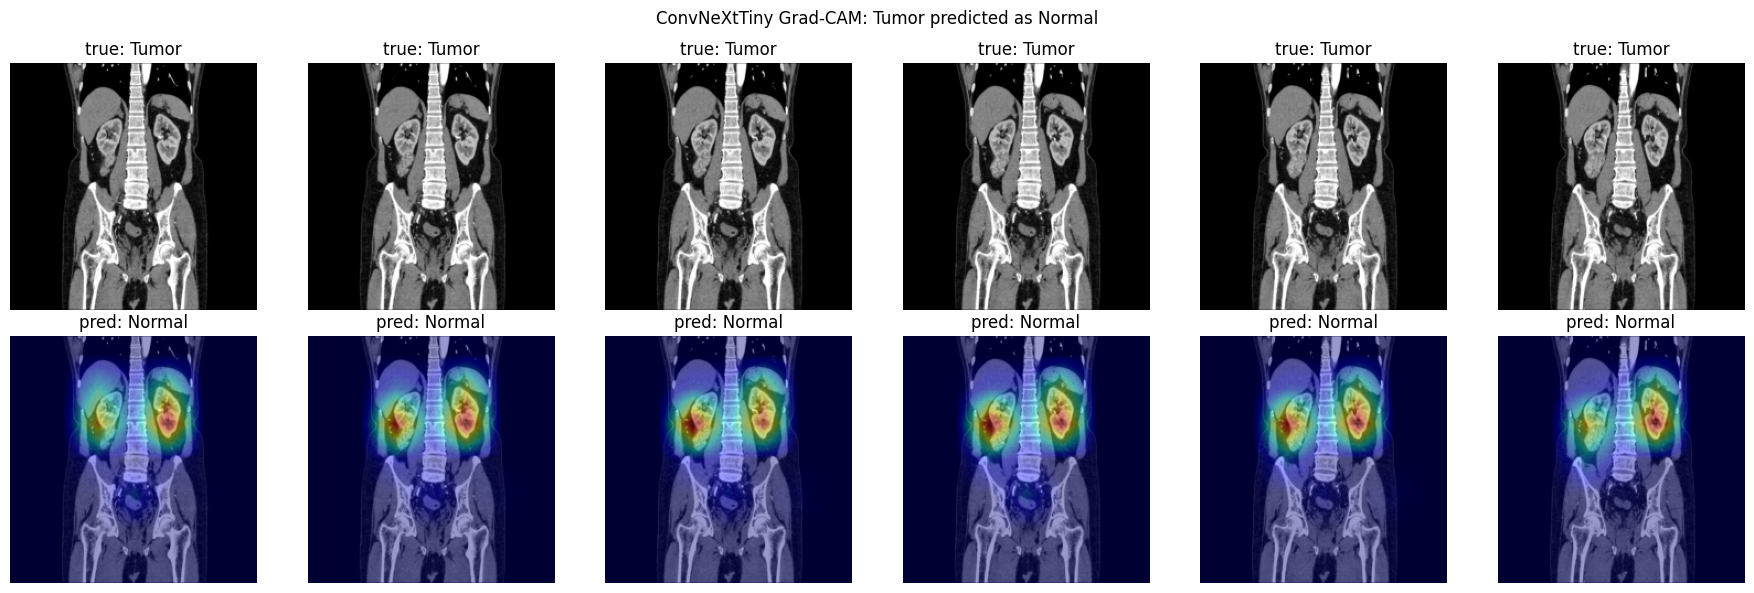

In [ ]:
cnx = load('convnexttiny', 'convnext_tiny')
cfg = timm.data.resolve_data_config({}, model=cnx)
d, dl = make_loaders(cfg['mean'], cfg['std'])
classes = d['test'].classes
_, yt, yp = evaluate(cnx, dl['test'])
yt, yp = np.array(yt), np.array(yp)
bad = np.where((yt == classes.index('Tumor')) & (yp == classes.index('Normal')))[0][:6]

fig, ax = plt.subplots(2, len(bad), figsize=(3 * len(bad), 6))
for k, i in enumerate(bad):
    x, y = d['test'][i]
    cam, cls = gradcam(cnx, cnx.stages[-1], x[None].to(device))
    img = denorm(x, cfg)
    cam224 = F.interpolate(torch.tensor(cam)[None, None], size=224, mode='bilinear')[0, 0].numpy()
    ax[0, k].imshow(img); ax[0, k].set_title(f'true: {classes[y]}'); ax[0, k].axis('off')
    ax[1, k].imshow(img); ax[1, k].imshow(cam224, cmap='jet', alpha=0.4); ax[1, k].set_title(f'pred: {classes[cls]}'); ax[1, k].axis('off')
plt.suptitle('ConvNeXtTiny Grad-CAM: Tumor predicted as Normal'); plt.tight_layout()
plt.savefig('/content/gradcam_convnext_tumor_as_normal.png', dpi=150); plt.show()

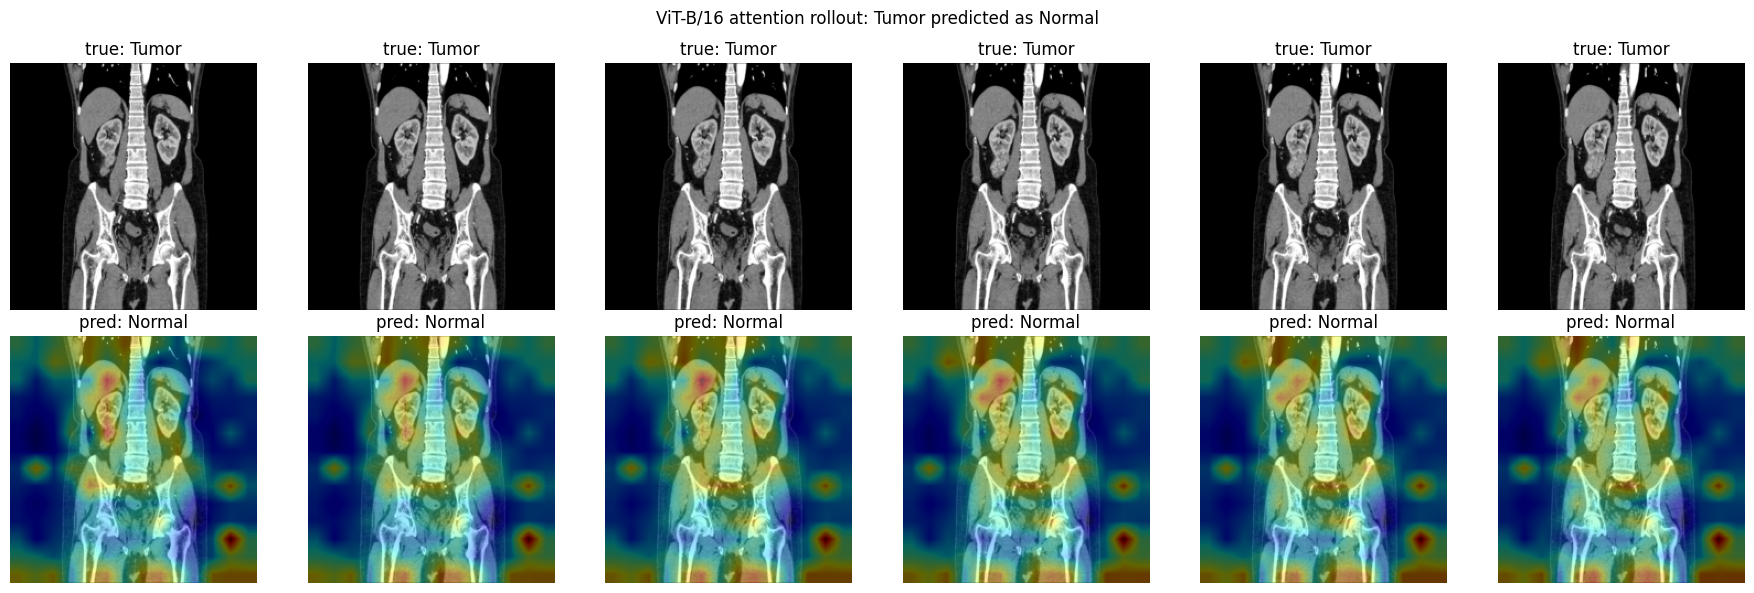

In [ ]:
vit = load('vit_b16', 'vit_base_patch16_224')
cfgv = timm.data.resolve_data_config({}, model=vit)
dv, dlv = make_loaders(cfgv['mean'], cfgv['std'])
_, ytv, ypv = evaluate(vit, dlv['test'])
ytv, ypv = np.array(ytv), np.array(ypv)
badv = np.where((ytv == classes.index('Tumor')) & (ypv == classes.index('Normal')))[0][:6]

def rollout(model, x):
    atts = []
    hs = []
    for blk in model.blocks:
        blk.attn.fused_attn = False
        hs.append(blk.attn.attn_drop.register_forward_hook(lambda m, i, o: atts.append(o.detach().cpu())))
    with torch.no_grad():
        out = model(x)
    for h in hs: h.remove()
    r = torch.eye(atts[0].shape[-1])
    for a in atts:
        a = a.mean(1)[0] + torch.eye(a.shape[-1])
        r = (a / a.sum(-1, keepdim=True)) @ r
    m = r[0, 1:].reshape(14, 14)
    return (m / m.max()).numpy(), out.argmax(1).item()

fig, ax = plt.subplots(2, len(badv), figsize=(3 * len(badv), 6))
for k, i in enumerate(badv):
    x, y = dv['test'][i]
    m, cls = rollout(vit, x[None].to(device))
    img = denorm(x, cfgv)
    m224 = F.interpolate(torch.tensor(m)[None, None], size=224, mode='bilinear')[0, 0].numpy()
    ax[0, k].imshow(img); ax[0, k].set_title(f'true: {classes[y]}'); ax[0, k].axis('off')
    ax[1, k].imshow(img); ax[1, k].imshow(m224, cmap='jet', alpha=0.4); ax[1, k].set_title(f'pred: {classes[cls]}'); ax[1, k].axis('off')
plt.suptitle('ViT-B/16 attention rollout: Tumor predicted as Normal'); plt.tight_layout()
plt.savefig('/content/attention_vit_tumor_as_normal.png', dpi=150); plt.show()

### Error concentration: how many test clusters produce the errors

In [32]:
from collections import Counter
cl = np.array([lab[key[(classes[l], os.path.basename(p))]] for p, l in d['test'].samples])
for name, a, b in (('ConvNeXtTiny', yt, yp), ('ViT-B/16', ytv, ypv)):
    err = np.where(a != b)[0]
    c = Counter(cl[err])
    print(f'{name}: {len(err)} errors come from {len(c)} clusters (test has {len(set(cl))} clusters)')
    print('   clusters with most errors:', c.most_common(5))

ConvNeXtTiny: 52 errors come from 9 clusters (test has 111 clusters)
   clusters with most errors: [(np.int32(711), 15), (np.int32(710), 13), (np.int32(753), 9), (np.int32(742), 8), (np.int32(463), 3)]
ViT-B/16: 64 errors come from 5 clusters (test has 111 clusters)
   clusters with most errors: [(np.int32(711), 24), (np.int32(753), 18), (np.int32(710), 14), (np.int32(742), 6), (np.int32(85), 2)]


## 9. Class weighting
### Fold 2

In [31]:
run('convnexttiny', 'convnext_tiny', 5e-5, class_weights=True)
run('vit_b16', 'vit_base_patch16_224', 2e-5, class_weights=True)

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


convnexttiny_cw epoch 1/6  82s  val_acc 0.9529
convnexttiny_cw epoch 2/6  80s  val_acc 0.9584
convnexttiny_cw epoch 3/6  81s  val_acc 0.9529
convnexttiny_cw epoch 4/6  79s  val_acc 0.9664
convnexttiny_cw epoch 5/6  80s  val_acc 0.9657
convnexttiny_cw epoch 6/6  78s  val_acc 0.9682

convnexttiny_cw  TEST accuracy: 0.9684
              precision    recall  f1-score   support

        Cyst       0.94      1.00      0.97       337
      Normal       0.96      1.00      0.98      1239
       Stone       1.00      1.00      1.00       127
       Tumor       1.00      0.86      0.92       483

    accuracy                           0.97      2186
   macro avg       0.98      0.96      0.97      2186
weighted avg       0.97      0.97      0.97      2186

[[ 337    0    0    0]
 [   0 1237    0    2]
 [   0    0  127    0]
 [  20   47    0  416]]


/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


vit_b16_cw epoch 1/6  90s  val_acc 0.9046
vit_b16_cw epoch 2/6  89s  val_acc 0.8557
vit_b16_cw epoch 3/6  89s  val_acc 0.9529
vit_b16_cw epoch 4/6  94s  val_acc 0.9547
vit_b16_cw epoch 5/6  94s  val_acc 0.9584
vit_b16_cw epoch 6/6  93s  val_acc 0.9596

vit_b16_cw  TEST accuracy: 0.9703
              precision    recall  f1-score   support

        Cyst       0.99      0.99      0.99       337
      Normal       0.97      0.98      0.98      1239
       Stone       0.98      0.98      0.98       127
       Tumor       0.95      0.93      0.94       483

    accuracy                           0.97      2186
   macro avg       0.97      0.97      0.97      2186
weighted avg       0.97      0.97      0.97      2186

[[ 334    0    3    0]
 [   0 1214    0   25]
 [   2    0  125    0]
 [   2   33    0  448]]


### Fold 1

In [33]:
SPLIT = '/content/split_group'
OUT = '/content/drive/MyDrive/Thesis /Final /results_group'
run('convnexttiny', 'convnext_tiny', 5e-5, class_weights=True)
run('vit_b16', 'vit_base_patch16_224', 2e-5, class_weights=True)

/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


convnexttiny_cw epoch 1/6  96s  val_acc 0.9736
convnexttiny_cw epoch 2/6  86s  val_acc 0.9695
convnexttiny_cw epoch 3/6  85s  val_acc 0.9979
convnexttiny_cw epoch 4/6  86s  val_acc 0.9986
convnexttiny_cw epoch 5/6  84s  val_acc 0.9993
convnexttiny_cw epoch 6/6  85s  val_acc 0.9993

convnexttiny_cw  TEST accuracy: 0.9211
              precision    recall  f1-score   support

        Cyst       0.98      0.83      0.90       503
      Normal       0.92      1.00      0.96       505
       Stone       0.81      0.97      0.88       359
       Tumor       1.00      0.87      0.93       331

    accuracy                           0.92      1698
   macro avg       0.93      0.92      0.92      1698
weighted avg       0.93      0.92      0.92      1698

[[420   0  83   0]
 [  0 505   0   0]
 [  9   0 350   0]
 [  0  42   0 289]]


/tmp/ipykernel_3050/2606131406.py:42: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_3050/2606131406.py:52: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


vit_b16_cw epoch 1/6  94s  val_acc 0.9674
vit_b16_cw epoch 2/6  95s  val_acc 0.8856
vit_b16_cw epoch 3/6  94s  val_acc 0.9598
vit_b16_cw epoch 4/6  95s  val_acc 0.9868
vit_b16_cw epoch 5/6  99s  val_acc 0.9965
vit_b16_cw epoch 6/6  100s  val_acc 0.9945

vit_b16_cw  TEST accuracy: 0.9217
              precision    recall  f1-score   support

        Cyst       0.95      0.86      0.90       503
      Normal       0.93      1.00      0.96       505
       Stone       0.83      0.87      0.85       359
       Tumor       0.98      0.94      0.96       331

    accuracy                           0.92      1698
   macro avg       0.92      0.92      0.92      1698
weighted avg       0.92      0.92      0.92      1698

[[434   0  63   6]
 [  0 505   0   0]
 [ 25  20 314   0]
 [  0  19   0 312]]


## 10. Seed repeats
ConvNeXtTiny and ViT-B/16 re-trained with seeds 1 and 2. `run(...)` now takes a `seed` argument.

In [35]:
import random

def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

def run(name, timm_name, lr, epochs=6, class_weights=False, seed=42):
    set_seed(seed)
    m = timm.create_model(timm_name, pretrained=True, num_classes=4).to(device)
    cfg = timm.data.resolve_data_config({}, model=m)
    d, dl = make_loaders(cfg['mean'], cfg['std'])
    classes = d['train'].classes
    w = None
    if class_weights:
        y = [s[1] for s in d['train'].samples]
        w = compute_class_weight('balanced', classes=np.unique(y), y=y)
        w = torch.tensor(w, dtype=torch.float).to(device)
    crit = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.01)
    steps = epochs * len(dl['train'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    scaler = torch.amp.GradScaler('cuda')
    tag = name
    if class_weights:
        tag += '_cw'
    if seed != 42:
        tag += f'_s{seed}'
    best = 0
    for ep in range(epochs):
        m.train()
        t0 = time.time()
        for x, y in dl['train']:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.autocast('cuda', dtype=torch.float16):
                loss = crit(m(x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
        va = evaluate(m, dl['val'])[0]
        print(f'{tag} epoch {ep+1}/{epochs}  {time.time()-t0:.0f}s  val_acc {va:.4f}')
        if va > best:
            best = va
            torch.save(m.state_dict(), f'{OUT}/{tag}.pth')
    m.load_state_dict(torch.load(f'{OUT}/{tag}.pth'))
    acc, yt, yp = evaluate(m, dl['test'])
    rep = classification_report(yt, yp, target_names=classes, output_dict=True)
    cm = confusion_matrix(yt, yp)
    print(f'\n{tag}  TEST accuracy: {acc:.4f}')
    print(classification_report(yt, yp, target_names=classes))
    print(cm)
    result = {'acc': acc, 'report': rep, 'cm': cm.tolist()}
    with open(f'{OUT}/{tag}.json', 'w') as f:
        json.dump(result, f)
    del m
    torch.cuda.empty_cache()

### Helper: run both models on one fold

In [36]:
def run_pair(fold, seed):
    global SPLIT, OUT
    SPLIT = {'fold1': '/content/split_group', 'fold2': '/content/split_group2'}[fold]
    OUT = '/content/drive/MyDrive/Thesis /Final /' + {'fold1': 'results_group', 'fold2': 'results_group2'}[fold]
    run('convnexttiny', 'convnext_tiny', 5e-5, seed=seed)
    run('vit_b16', 'vit_base_patch16_224', 2e-5, seed=seed)

### Fold 2, seed 1

In [37]:
run_pair('fold2', 1)

/tmp/ipykernel_3050/2492999002.py:42: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


convnexttiny_s1 epoch 1/6  92s  val_acc 0.8997
convnexttiny_s1 epoch 2/6  84s  val_acc 0.9896
convnexttiny_s1 epoch 3/6  82s  val_acc 0.9780
convnexttiny_s1 epoch 4/6  80s  val_acc 0.9890
convnexttiny_s1 epoch 5/6  78s  val_acc 0.9902
convnexttiny_s1 epoch 6/6  82s  val_acc 0.9902

convnexttiny_s1  TEST accuracy: 0.9886
              precision    recall  f1-score   support

        Cyst       0.97      1.00      0.98       337
      Normal       0.99      1.00      0.99      1239
       Stone       1.00      1.00      1.00       127
       Tumor       1.00      0.95      0.97       483

    accuracy                           0.99      2186
   macro avg       0.99      0.99      0.99      2186
weighted avg       0.99      0.99      0.99      2186

[[ 337    0    0    0]
 [   0 1239    0    0]
 [   0    0  127    0]
 [  11   14    0  458]]
vit_b16_s1 epoch 1/6  90s  val_acc 0.9523
vit_b16_s1 epoch 2/6  91s  val_acc 0.9670
vit_b16_s1 epoch 3/6  93s  val_acc 0.9927
vit_b16_s1 epoch 4/6  95

### Fold 2, seed 2

In [38]:
run_pair('fold2', 2)

/tmp/ipykernel_3050/2492999002.py:42: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


convnexttiny_s2 epoch 1/6  78s  val_acc 0.9609
convnexttiny_s2 epoch 2/6  79s  val_acc 0.9774
convnexttiny_s2 epoch 3/6  82s  val_acc 0.9761
convnexttiny_s2 epoch 4/6  78s  val_acc 0.9914
convnexttiny_s2 epoch 5/6  80s  val_acc 0.9841
convnexttiny_s2 epoch 6/6  78s  val_acc 0.9835

convnexttiny_s2  TEST accuracy: 0.9835
              precision    recall  f1-score   support

        Cyst       0.97      0.99      0.98       337
      Normal       0.98      1.00      0.99      1239
       Stone       0.98      0.99      0.98       127
       Tumor       1.00      0.93      0.97       483

    accuracy                           0.98      2186
   macro avg       0.98      0.98      0.98      2186
weighted avg       0.98      0.98      0.98      2186

[[ 334    0    3    0]
 [   0 1239    0    0]
 [   1    0  126    0]
 [   8   24    0  451]]


/tmp/ipykernel_3050/2492999002.py:42: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


vit_b16_s2 epoch 1/6  90s  val_acc 0.9676
vit_b16_s2 epoch 2/6  90s  val_acc 0.9627
vit_b16_s2 epoch 3/6  89s  val_acc 0.9872
vit_b16_s2 epoch 4/6  96s  val_acc 0.9927
vit_b16_s2 epoch 5/6  94s  val_acc 0.9945
vit_b16_s2 epoch 6/6  94s  val_acc 0.9951

vit_b16_s2  TEST accuracy: 0.9840
              precision    recall  f1-score   support

        Cyst       0.97      1.00      0.99       337
      Normal       0.98      1.00      0.99      1239
       Stone       1.00      0.95      0.98       127
       Tumor       1.00      0.94      0.97       483

    accuracy                           0.98      2186
   macro avg       0.99      0.97      0.98      2186
weighted avg       0.98      0.98      0.98      2186

[[ 337    0    0    0]
 [   0 1239    0    0]
 [   6    0  121    0]
 [   4   25    0  454]]


### Fold 1, seed 1

In [39]:
run_pair('fold1', 1)

/tmp/ipykernel_3050/2492999002.py:42: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


convnexttiny_s1 epoch 1/6  83s  val_acc 0.9376
convnexttiny_s1 epoch 2/6  83s  val_acc 0.9938
convnexttiny_s1 epoch 3/6  86s  val_acc 0.9840
convnexttiny_s1 epoch 4/6  80s  val_acc 0.9938
convnexttiny_s1 epoch 5/6  82s  val_acc 0.9882
convnexttiny_s1 epoch 6/6  80s  val_acc 0.9889

convnexttiny_s1  TEST accuracy: 0.8963
              precision    recall  f1-score   support

        Cyst       0.97      0.85      0.91       503
      Normal       0.85      1.00      0.92       505
       Stone       0.82      0.94      0.88       359
       Tumor       1.00      0.76      0.86       331

    accuracy                           0.90      1698
   macro avg       0.91      0.89      0.89      1698
weighted avg       0.91      0.90      0.90      1698

[[429   1  73   0]
 [  0 505   0   0]
 [ 15   7 337   0]
 [  0  80   0 251]]


/tmp/ipykernel_3050/2492999002.py:42: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


vit_b16_s1 epoch 1/6  93s  val_acc 0.9840
vit_b16_s1 epoch 2/6  95s  val_acc 0.9646
vit_b16_s1 epoch 3/6  93s  val_acc 0.9036
vit_b16_s1 epoch 4/6  93s  val_acc 0.9813
vit_b16_s1 epoch 5/6  94s  val_acc 0.9792
vit_b16_s1 epoch 6/6  93s  val_acc 0.9792

vit_b16_s1  TEST accuracy: 0.8881
              precision    recall  f1-score   support

        Cyst       0.91      0.80      0.85       503
      Normal       0.91      1.00      0.95       505
       Stone       0.76      0.86      0.81       359
       Tumor       1.00      0.88      0.93       331

    accuracy                           0.89      1698
   macro avg       0.89      0.89      0.89      1698
weighted avg       0.90      0.89      0.89      1698

[[403   0 100   0]
 [  0 505   0   0]
 [ 39  10 310   0]
 [  0  41   0 290]]


### Fold 1, seed 2

In [40]:
run_pair('fold1', 2)

/tmp/ipykernel_3050/2492999002.py:42: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


convnexttiny_s2 epoch 1/6  81s  val_acc 0.9910
convnexttiny_s2 epoch 2/6  85s  val_acc 0.9903
convnexttiny_s2 epoch 3/6  82s  val_acc 0.9882
convnexttiny_s2 epoch 4/6  83s  val_acc 0.9945
convnexttiny_s2 epoch 5/6  85s  val_acc 0.9910
convnexttiny_s2 epoch 6/6  81s  val_acc 0.9917

convnexttiny_s2  TEST accuracy: 0.9193
              precision    recall  f1-score   support

        Cyst       0.95      0.84      0.89       503
      Normal       0.94      1.00      0.97       505
       Stone       0.81      0.93      0.87       359
       Tumor       1.00      0.89      0.94       331

    accuracy                           0.92      1698
   macro avg       0.92      0.92      0.92      1698
weighted avg       0.92      0.92      0.92      1698

[[425   0  78   0]
 [  0 505   0   0]
 [ 24   0 335   0]
 [  0  35   0 296]]


/tmp/ipykernel_3050/2492999002.py:42: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


vit_b16_s2 epoch 1/6  96s  val_acc 0.9147
vit_b16_s2 epoch 2/6  95s  val_acc 0.9723
vit_b16_s2 epoch 3/6  101s  val_acc 0.9792
vit_b16_s2 epoch 4/6  101s  val_acc 0.9757
vit_b16_s2 epoch 5/6  94s  val_acc 0.9889
vit_b16_s2 epoch 6/6  99s  val_acc 0.9889

vit_b16_s2  TEST accuracy: 0.9122
              precision    recall  f1-score   support

        Cyst       0.92      0.82      0.87       503
      Normal       0.96      1.00      0.98       505
       Stone       0.78      0.89      0.83       359
       Tumor       1.00      0.94      0.97       331

    accuracy                           0.91      1698
   macro avg       0.91      0.91      0.91      1698
weighted avg       0.92      0.91      0.91      1698

[[411   0  92   0]
 [  0 505   0   0]
 [ 34   4 321   0]
 [  0  19   0 312]]


### Summary: mean ± SD over three seeds (42, 1, 2)

In [41]:
import glob
def collect(folder, base):
    accs = {}
    for f in glob.glob(f'/content/drive/MyDrive/Thesis /Final /{folder}/{base}*.json'):
        tag = os.path.basename(f)[:-5]
        if tag == base or tag.startswith(base + '_s'):
            accs[tag] = json.load(open(f))['acc'] * 100
    return accs

for folder in ('results_group', 'results_group2'):
    for base in ('convnexttiny', 'vit_b16'):
        a = collect(folder, base)
        v = np.array(list(a.values()))
        print(folder, base, {k: round(x, 2) for k, x in a.items()}, f'-> mean {v.mean():.2f} ± {v.std(ddof=1):.2f}')

results_group convnexttiny {'convnexttiny': 97.0, 'convnexttiny_s1': 89.63, 'convnexttiny_s2': 91.93} -> mean 92.85 ± 3.77
results_group vit_b16 {'vit_b16': 92.93, 'vit_b16_s1': 88.81, 'vit_b16_s2': 91.22} -> mean 90.99 ± 2.07
results_group2 convnexttiny {'convnexttiny': 97.62, 'convnexttiny_s1': 98.86, 'convnexttiny_s2': 98.35} -> mean 98.28 ± 0.62
results_group2 vit_b16 {'vit_b16': 97.07, 'vit_b16_s1': 97.53, 'vit_b16_s2': 98.4} -> mean 97.67 ± 0.67


## Results at a glance (test accuracy, %)

| Setting | ConvNeXtTiny | ViT-B/16 | ResNet50 | EfficientNetB0 |
|---|---|---|---|---|
| Random split, exact duplicates removed (n=1,793) | 99.89 | 99.83 | 99.33 | 99.89 |
| Cluster fold 1 (n=1,698), seed 42 | 97.00 | 92.93 | 90.58 | 78.45 |
| Cluster fold 2 (n=2,186), seed 42 | 97.62 | 97.07 | 90.76 | 89.39 |
| Fold 1, mean ± SD over seeds 42, 1, 2 | 92.85 ± 3.77 | 90.99 ± 2.07 | single run | single run |
| Fold 2, mean ± SD over seeds 42, 1, 2 | 98.28 ± 0.62 | 97.67 ± 0.67 | single run | single run |

Class weighting (single run each): fold 1, ConvNeXtTiny 92.11 and ViT-B/16 92.17; fold 2, ConvNeXtTiny 96.84 and ViT-B/16 97.03.

Reading guide: on the random split every model reaches about 99-100%, because near-identical slices appear in both train and test. On the cluster-aware folds the models separate, but ConvNeXtTiny and ViT-B/16 are not clearly different once seed-to-seed variation is considered.